# Практика 2. MLflow: журнал экспериментов и реестр моделей

**Перед началом:** этот файл только для чтения и общий для всей группы.
Сохраните свою копию: **File → Save Notebook As…** → `work/students/<ваше_имя>/02_mlflow.ipynb`.

Веб-интерфейс MLflow: **http://10.162.1.86:5000** — войдите своим логином, держите вкладку открытой
и смотрите, как после каждой ячейки там появляются запуски.

План:
1. Установка
2. Подключение со своим логином
3. **Первые шаги: от простого к сложному** — один запуск, несколько подряд, ветвление на два параллельных
4. Главные понятия
5. Эксперимент на настоящих данных
6. Артефакты: графики, отчёты, файлы
7. Сохранение и загрузка модели
8. Перебор параметров и поиск лучшего запуска
9. Метрики по эпохам (как в deep learning)
10. Реестр моделей: версии и метка `champion`
11. Автологирование
12. **Задачи**
**Выполненное решение.** По умолчанию `LAB_MODE=local`: настоящий MLflow с локальной базой SQLite и файловыми артефактами. Для учебного сервера установите `LAB_MODE=remote`, `MLFLOW_TRACKING_URI`, `MLFLOW_TRACKING_USERNAME`, `MLFLOW_TRACKING_PASSWORD`. Пароли в ноутбуке не сохраняются.


## 1. Установка

- **mlflow-skinny** — лёгкий клиент MLflow (без веб-сервера: сервер у нас уже запущен). Версия клиента должна
  совпадать с версией сервера — у нас **3.16.1**.
- **skops** — безопасный формат сохранения моделей sklearn, его использует MLflow 3.

На сервере всё установлено, команда только проверит.

In [1]:
%pip install -q "mlflow==3.16.1" skops scikit-learn matplotlib pandas


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: C:\Users\Enot\PycharmProjects\ML_lab1n2\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import mlflow
print("mlflow", mlflow.__version__)

2026/11/13 00:52:30 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Enot\PycharmProjects\ML_lab1n2\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


mlflow 3.16.1


## 2. Подключение

| Что | Значение |
|---|---|
| адрес сервера (`MLFLOW_TRACKING_URI`) | внутри сервера `http://mlflow:5000`, снаружи `http://10.162.1.86:5000` |
| логин (`MLFLOW_TRACKING_USERNAME`) | ваш логин: `user1` … `user30` |
| пароль (`MLFLOW_TRACKING_PASSWORD`) | выдаёт преподаватель |

MLflow берёт адрес, логин и пароль **из переменных окружения** — так устроен клиент MLflow:

| Переменная | Что в ней |
|---|---|
| `MLFLOW_TRACKING_URI` | адрес сервера MLflow |
| `MLFLOW_TRACKING_USERNAME` | логин |
| `MLFLOW_TRACKING_PASSWORD` | пароль |

Пароль вводим через `getpass` — в коде его нет.

> Работаете **на своём компьютере** (VS Code, Anaconda)? Адрес `http://mlflow:5000` там не работает —
> это внутреннее имя сервера. Ячейка ниже сама возьмёт внешний адрес `http://10.162.1.86:5000`.

**Права:** вы видите эксперименты всей группы, но менять можете только **свои**.
Поэтому все имена начинаем со своего логина: `user7_wine`, `user7_wine_model`.

In [3]:
import os
from pathlib import Path
from getpass import getpass

LAB_MODE = os.environ.get("LAB_MODE", "local").lower()
if LAB_MODE == "local":
    MLFLOW_USER = "local_student"
    tracking_db = Path("lab_artifacts/mlflow/mlflow.db").resolve()
    tracking_db.parent.mkdir(parents=True, exist_ok=True)
    mlflow.set_tracking_uri("sqlite:///" + tracking_db.as_posix())
    UI = "http://127.0.0.1:5000"
elif LAB_MODE == "remote":
    MLFLOW_USER = os.environ.get("MLFLOW_TRACKING_USERNAME") or input("Логин MLflow (userN): ").strip()
    os.environ["MLFLOW_TRACKING_USERNAME"] = MLFLOW_USER
    os.environ["MLFLOW_TRACKING_PASSWORD"] = (
        os.environ.get("MLFLOW_TRACKING_PASSWORD") or os.environ.get("NB_MLFLOW_PASSWORD")
        or getpass(f"Пароль MLflow для {MLFLOW_USER}: "))
    mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "http://10.162.1.86:5000"))
    UI = os.environ.get("MLFLOW_UI_URL", "http://10.162.1.86:5000")
else:
    raise ValueError("LAB_MODE должен быть local или remote")

print("Режим:", LAB_MODE, "| tracking:", mlflow.get_tracking_uri(), "| логин:", MLFLOW_USER)
if LAB_MODE == "local":
    print("Для интерфейса выполните из папки проекта:")
    print(f'.venv\\Scripts\\python.exe -m mlflow ui --backend-store-uri "{mlflow.get_tracking_uri()}" --port 5000')
    print("Затем откройте", UI)


Режим: local | tracking: sqlite:///C:/Users/Enot/PycharmProjects/ML_lab1n2/lab_artifacts/mlflow/mlflow.db | логин: local_student
Для интерфейса выполните из папки проекта:
.venv\Scripts\python.exe -m mlflow ui --backend-store-uri "sqlite:///C:/Users/Enot/PycharmProjects/ML_lab1n2/lab_artifacts/mlflow/mlflow.db" --port 5000
Затем откройте http://127.0.0.1:5000


In [4]:
# проверка связи: 5 последних экспериментов на сервере
for e in mlflow.search_experiments(max_results=5, order_by=["last_update_time DESC"]):
    print(e.experiment_id, e.name)

2026/11/13 00:52:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/13 00:52:30 INFO mlflow.store.db.utils: Updating database tables


0 Default


## 3. Первые шаги: от простого к сложному

Прежде чем обучать модели, посмотрим, как MLflow записывает запуски, на самых простых примерах.
Держите открытой вкладку **http://10.162.1.86:5000** и после каждой ячейки обновляйте страницу.

### 3.1 Один запуск
Минимум, который нужен MLflow: **эксперимент** (папка) и **запуск** внутри него.

In [5]:
mlflow.set_experiment(f"{MLFLOW_USER}_first_steps")       # папка для запусков (создастся сама)

with mlflow.start_run(run_name="step1_hello"):             # один запуск
    mlflow.log_param("learning_rate", 0.1)                 # параметр: с чем запускали
    mlflow.log_metric("accuracy", 0.85)                    # метрика: что получилось

print("готово — в интерфейсе появился эксперимент", f"{MLFLOW_USER}_first_steps", "и в нём 1 запуск")

2026/11/13 00:52:32 INFO mlflow.tracking.fluent: Experiment with name 'local_student_first_steps' does not exist. Creating a new experiment.


готово — в интерфейсе появился эксперимент local_student_first_steps и в нём 1 запуск


### 3.2 Несколько запусков подряд
Каждая итерация цикла — **отдельный запуск**. Так делают, когда перебирают параметры:
в интерфейсе запуски встанут строками таблицы, и их можно сравнить.

In [6]:
for lr in [0.001, 0.01, 0.1]:
    with mlflow.start_run(run_name=f"step2_lr_{lr}"):
        mlflow.log_param("learning_rate", lr)
        mlflow.log_metric("accuracy", round(0.7 + lr, 3))  # «результат» — пока просто число
        print("запуск с learning_rate =", lr)

runs = mlflow.search_runs(experiment_names=[f"{MLFLOW_USER}_first_steps"], order_by=["start_time ASC"])
runs[["tags.mlflow.runName", "params.learning_rate", "metrics.accuracy"]]

запуск с learning_rate = 0.001
запуск с learning_rate = 0.01
запуск с learning_rate = 0.1


,tags.mlflow.runName,params.learning_rate,metrics.accuracy
0,step1_hello,0.1,0.850
1,step2_lr_0.001,0.001,0.701
2,step2_lr_0.01,0.01,0.710
3,step2_lr_0.1,0.1,0.800


### 3.3 Один запуск разветвляется на два
Часто один шаг готовит данные, а дальше из них обучают **несколько моделей**.
В MLflow это **родительский запуск** с **дочерними** (`nested=True`):

```
pipeline (родитель: данные)
 ├── logreg          (дочерний)
 └── decision_tree   (дочерний)
```
В интерфейсе дочерние запуски спрятаны под родителем — нажмите «+» слева от `pipeline`.

In [7]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

X, y = load_wine(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

with mlflow.start_run(run_name="step3_pipeline"):                          # РОДИТЕЛЬ: данные
    mlflow.log_params({"dataset": "wine", "train_rows": len(X_train), "test_rows": len(X_test)})

    with mlflow.start_run(run_name="logreg", nested=True):                 # ребёнок 1
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train, y_train)
        mlflow.log_metric("f1_macro", f1_score(y_test, m.predict(X_test), average="macro"))

    with mlflow.start_run(run_name="decision_tree", nested=True):          # ребёнок 2
        m = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_train, y_train)
        mlflow.log_metric("f1_macro", f1_score(y_test, m.predict(X_test), average="macro"))

print("родитель и 2 дочерних запуска записаны")

родитель и 2 дочерних запуска записаны


### 3.4 Два дочерних запуска параллельно, результат — обратно в родителя
В 3.3 модели обучались **по очереди**. Если модели обучаются долго (нейросети — часами),
их запускают **одновременно**. После этого родитель собирает результаты и записывает лучшую модель:

```
                ┌──► logreg          ─┐
step4_pipeline ─┤                     ├──► лучшая модель → в родителя
                └──► decision_tree   ─┘
```
Каждый поток открывает свой дочерний запуск и явно указывает родителя (`parent_run_id`).

In [8]:
import time
from concurrent.futures import ThreadPoolExecutor

def train_child(name, model, parent_id):
    """Обучает одну модель в своём дочернем запуске. Возвращает (имя, f1, время старта, время конца)."""
    with mlflow.start_run(run_name=name, parent_run_id=parent_id, nested=True):
        start = time.time()
        model.fit(X_train, y_train)
        time.sleep(2)                                       # имитация долгого обучения
        f1 = f1_score(y_test, model.predict(X_test), average="macro")
        mlflow.log_metric("f1_macro", f1)
        return name, f1, start, time.time()

models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "decision_tree": DecisionTreeClassifier(max_depth=2, random_state=42),
}

with mlflow.start_run(run_name="step4_parallel") as parent:
    mlflow.log_param("dataset", "wine")
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=2) as pool:                        # два потока одновременно
        results = list(pool.map(lambda item: train_child(*item, parent.info.run_id), models.items()))

    best_name, best_f1, _, _ = max(results, key=lambda r: r[1])           # сбор результатов
    mlflow.log_params({"best_model": best_name})
    mlflow.log_metric("best_f1", best_f1)

for name, f1, start, end in results:
    print(f"{name:<14} f1={f1:.3f}   обучение с {start - t0:.1f} по {end - t0:.1f} с")
parallel = max(r[3] for r in results) - min(r[2] for r in results)     # от первого старта до последнего конца
one_by_one = sum(r[3] - r[2] for r in results)                          # если бы обучали по очереди
print(f"обучение заняло {parallel:.1f} с, по очереди было бы {one_by_one:.1f} с | лучшая: {best_name}")

logreg         f1=1.000   обучение с 0.0 по 2.0 с
decision_tree  f1=0.879   обучение с 0.0 по 2.1 с
обучение заняло 2.0 с, по очереди было бы 4.0 с | лучшая: logreg


Посмотрите: обе модели начали и закончили **в одно время** — они шли параллельно.
Это та же схема, по которой в Airflow одна задача раздаёт работу нескольким параллельным задачам,
а следующая задача собирает результаты. Дальше разберём всё подробно на настоящих моделях.

## 4. Главные понятия

| Понятие | Что это | Пример |
|---|---|---|
| **Experiment** | папка для запусков одной задачи | `user7_wine` |
| **Run** | один запуск обучения | «логрегрессия, C=1» |
| **Params** | с чем обучали (входы) | `C=1.0`, `max_iter=5000` |
| **Metrics** | что получилось (числа, можно по шагам) | `accuracy=0.97` |
| **Tags** | подписи для поиска | `model_type=logreg` |
| **Artifacts** | файлы запуска | график, отчёт, модель |
| **Registered model** | модель в реестре с версиями | `user7_wine_model` v1, v2… |
| **Alias** | метка версии | `@champion` — основная |

## 5. Эксперимент на настоящих данных

`set_experiment` выбирает эксперимент (и создаёт, если его нет). Всё, что внутри `with mlflow.start_run():`,
попадает в один запуск.

> После каждого запуска MLflow сам печатает строку `🏃 View run … at: http://mlflow:5000/…`.
> `mlflow` — внутреннее имя сервера, из браузера оно не откроется. Открывайте ссылки, которые печатаем мы
> (с адресом `http://10.162.1.86:5000`), или замените в ссылке `mlflow` на `10.162.1.86`.

In [9]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

X, y = load_wine(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

EXPERIMENT = f"{MLFLOW_USER}_wine"
exp = mlflow.set_experiment(EXPERIMENT)
print("эксперимент:", exp.name, "id =", exp.experiment_id)

2026/11/13 00:52:36 INFO mlflow.tracking.fluent: Experiment with name 'local_student_wine' does not exist. Creating a new experiment.


эксперимент: local_student_wine id = 2


In [10]:
params = {"C": 1.0, "max_iter": 5000}

with mlflow.start_run(run_name="logreg_C1") as run:
    mlflow.log_params(params)                                   # 1) с чем обучали
    mlflow.set_tag("model_type", "logreg")                      # 2) подпись для поиска

    model = make_pipeline(StandardScaler(), LogisticRegression(**params)).fit(X_train, y_train)
    pred = model.predict(X_test)

    mlflow.log_metrics({                                        # 3) что получилось
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
    })

print("run id:", run.info.run_id)
print("открыть в браузере:", f"{UI}/#/experiments/{exp.experiment_id}/runs/{run.info.run_id}")

run id: c4d2d1a65ef24ada98437d37c66fc7fa
открыть в браузере: http://127.0.0.1:5000/#/experiments/2/runs/c4d2d1a65ef24ada98437d37c66fc7fa


## 6. Артефакты

Артефакт — любой файл запуска. Файлы MLflow сам кладёт в S3 (бакет `mlflow`), вам ключи S3 не нужны.

| Команда | Что сохраняет |
|---|---|
| `mlflow.log_figure(fig, "cm.png")` | график matplotlib |
| `mlflow.log_dict(d, "report.json")` | словарь как JSON |
| `mlflow.log_text(s, "notes.txt")` | строку как текстовый файл |
| `mlflow.log_artifact("путь")` | любой файл с диска |

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

with mlflow.start_run(run_name="logreg_with_artifacts") as run:
    mlflow.log_params(params)
    model = make_pipeline(StandardScaler(), LogisticRegression(**params)).fit(X_train, y_train)
    pred = model.predict(X_test)
    mlflow.log_metric("accuracy", accuracy_score(y_test, pred))

    disp = ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
    mlflow.log_figure(disp.figure_, "confusion_matrix.png")      # график
    plt.close(disp.figure_)

    mlflow.log_dict(classification_report(y_test, pred, output_dict=True), "report.json")   # отчёт
    mlflow.log_text("Базовая модель для сравнения. Данные: sklearn wine.", "notes.txt")      # заметка

client = mlflow.MlflowClient()
print([a.path for a in client.list_artifacts(run.info.run_id)])

['confusion_matrix.png', 'notes.txt', 'report.json']


## 7. Сохранение и загрузка модели

`mlflow.sklearn.log_model` сохраняет модель в запуск вместе с описанием входа (`signature`) и примером данных.
MLflow 3 пишет модели sklearn в безопасном формате **skops**, и ему нужно заранее сказать, какие внутренние типы модели
считать безопасными — функция ниже считает их автоматически. Копируйте её как есть.

In [12]:
import skops.io as sio
from mlflow.models import infer_signature

def log_sklearn_model(model, X_example):
    """Сохраняет sklearn-модель в текущий запуск MLflow. Возвращает ModelInfo (в нём model_uri)."""
    return mlflow.sklearn.log_model(
        model,
        name="model",
        signature=infer_signature(X_example, model.predict(X_example)),
        input_example=X_example.head(3),
        skops_trusted_types=sio.get_untrusted_types(data=sio.dumps(model)),
    )

with mlflow.start_run(run_name="logreg_with_model") as run:
    mlflow.log_params(params)
    model = make_pipeline(StandardScaler(), LogisticRegression(**params)).fit(X_train, y_train)
    mlflow.log_metric("accuracy", accuracy_score(y_test, model.predict(X_test)))
    info = log_sklearn_model(model, X_test)

print("model_uri:", info.model_uri)

model_uri: models:/m-ebd1aac914c747baae582896f780d9b5


In [13]:
# загрузить модель обратно — на любом компьютере, где есть доступ к MLflow
loaded = mlflow.sklearn.load_model(info.model_uri)
print("прогноз загруженной модели:", loaded.predict(X_test.head(5)), "| правильно:", y_test.head(5).tolist())

прогноз загруженной модели: [0 1 0 0 1] | правильно: [0, 1, 0, 0, 1]


## 8. Перебор параметров и поиск лучшего

Один параметр — один запуск. Потом `search_runs` возвращает **все запуски таблицей pandas**:
их можно сортировать и фильтровать, как обычный DataFrame.

In [14]:
from sklearn.ensemble import RandomForestClassifier

for n in [5, 20, 100]:
    with mlflow.start_run(run_name=f"rf_{n}"):
        mlflow.set_tag("model_type", "random_forest")
        mlflow.log_param("n_estimators", n)
        rf = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
        mlflow.log_metric("f1_macro", f1_score(y_test, rf.predict(X_test), average="macro"))
        log_sklearn_model(rf, X_test)
print("готово")

готово


In [15]:
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT],
    filter_string="tags.model_type = 'random_forest'",
    order_by=["metrics.f1_macro DESC"],
)
runs[["run_id", "tags.mlflow.runName", "params.n_estimators", "metrics.f1_macro"]]

,run_id,tags.mlflow.runName,params.n_estimators,metrics.f1_macro
0,f923834a57e143c9a6e0c8449213b1fd,rf_100,100,1.000000
1,a05436e2c17b47119cdc2beff7e82ba1,rf_20,20,0.979724
2,1171d1a58f294a1fbc1c35483b6165e8,rf_5,5,0.936258


In [16]:
best = runs.iloc[0]
print("лучший запуск:", best["tags.mlflow.runName"], "f1 =", round(best["metrics.f1_macro"], 3))

лучший запуск: rf_100 f1 = 1.0


**В интерфейсе:** откройте эксперимент, отметьте галочками три запуска `rf_*` и нажмите **Compare** —
увидите параметры и метрики рядом и график зависимости f1 от числа деревьев.

## 9. Метрики по эпохам — как в deep learning

Нейросеть учится эпохами, и после каждой эпохи мы записываем метрику с номером шага `step`.
MLflow сам строит из этого **кривую обучения**. Покажем на `SGDClassifier`, который тоже учится по эпохам (`partial_fit`).

In [17]:
import numpy as np
from sklearn.linear_model import SGDClassifier

scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)
classes = np.unique(y_train)

with mlflow.start_run(run_name="sgd_epochs") as run:
    mlflow.log_params({"model": "SGDClassifier", "epochs": 30, "learning_rate": "optimal"})
    sgd = SGDClassifier(loss="log_loss", random_state=42)
    for epoch in range(30):
        sgd.partial_fit(Xtr, y_train, classes=classes)                      # одна эпоха
        mlflow.log_metrics({
            "train_accuracy": sgd.score(Xtr, y_train),
            "val_accuracy": sgd.score(Xte, y_test),
        }, step=epoch)                                                      # <- номер эпохи

history = mlflow.MlflowClient().get_metric_history(run.info.run_id, "val_accuracy")
print("val_accuracy по эпохам:", [round(m.value, 2) for m in history[:10]], "...")
print("график:", f"{UI}/#/experiments/{exp.experiment_id}/runs/{run.info.run_id}")

val_accuracy по эпохам: [0.93, 0.96, 0.93, 0.93, 0.93, 0.93, 0.93, 0.93, 0.93, 0.93] ...
график: http://127.0.0.1:5000/#/experiments/2/runs/4efc1f86d01c4487b63e4cff4322a97e


## 10. Реестр моделей: версии и метка `champion`

- `mlflow.register_model(uri, имя)` — сделать модель новой **версией** в реестре;
- `set_registered_model_alias(имя, "champion", версия)` — отметить основную версию;
- `load_model("models:/имя@champion")` — загрузить основную версию, **не зная её номера**.

Откатиться на старую версию = переставить метку. Код прогноза при этом не меняется.

In [18]:
MODEL_NAME = f"{MLFLOW_USER}_wine_model"
client = mlflow.MlflowClient()

version = mlflow.register_model(f"runs:/{best['run_id']}/model", MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "champion", version.version)
print(f"{MODEL_NAME}: версия {version.version} получила метку @champion")

Successfully registered model 'local_student_wine_model'.
2026/11/13 00:52:51 WARNING mlflow.tracking._model_registry.fluent: Run with id f923834a57e143c9a6e0c8449213b1fd has no artifacts at artifact path 'model', registering model based on models:/m-1c4421df558e448fa1f65c986b305fd3 instead


local_student_wine_model: версия 1 получила метку @champion


Created version '1' of model 'local_student_wine_model'.


In [19]:
champion = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")
print("прогноз чемпиона:", champion.predict(X_test.head(5)))

прогноз чемпиона: [0 1 0 0 1]


In [20]:
# все версии модели и их метки
for v in client.search_model_versions(f"name='{MODEL_NAME}'"):
    mv = client.get_model_version(MODEL_NAME, v.version)          # здесь есть метки (aliases)
    print("версия", mv.version, "| метки:", mv.aliases, "| из запуска", mv.run_id[:8])

версия 1 | метки: ['champion'] | из запуска f923834a


## 11. Автологирование

`mlflow.sklearn.autolog()` — MLflow сам записывает параметры, метрики на обучающей выборке и модель
при каждом `fit`. Удобно для быстрых экспериментов. Для PyTorch и Keras есть `mlflow.pytorch.autolog()`
и `mlflow.keras.autolog()`.

In [21]:
mlflow.sklearn.autolog(log_models=False)          # модель не сохраняем, только параметры и метрики

with mlflow.start_run(run_name="autolog_logreg") as run:
    make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000)).fit(X_train, y_train)

mlflow.sklearn.autolog(disable=True)              # выключаем, чтобы не мешало дальше
r = client.get_run(run.info.run_id)
print("параметров записано сами:", len(r.data.params), "| метрики:", list(r.data.metrics)[:4])

параметров записано сами: 23 | метрики: ['training_precision_score', 'training_recall_score', 'training_f1_score', 'training_accuracy_score']


C:\Users\Enot\PycharmProjects\ML_lab1n2\.venv\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


## Шпаргалка

| Действие | Команда |
|---|---|
| эксперимент | `mlflow.set_experiment(f"{MLFLOW_USER}_...")` |
| запуск | `with mlflow.start_run(run_name="..."):` |
| параметры / метрики | `mlflow.log_params({...})`, `mlflow.log_metrics({...}, step=epoch)` |
| подпись | `mlflow.set_tag("model_type", "rf")` |
| артефакты | `log_figure`, `log_dict`, `log_text`, `log_artifact` |
| модель | `mlflow.sklearn.log_model(...)` → `mlflow.sklearn.load_model(uri)` |
| все запуски | `mlflow.search_runs(experiment_names=[...], order_by=[...])` |
| история метрики | `MlflowClient().get_metric_history(run_id, "val_accuracy")` |
| реестр | `mlflow.register_model(uri, name)`, `set_registered_model_alias(name, "champion", v)` |
| загрузить основную | `mlflow.sklearn.load_model(f"models:/{name}@champion")` |

---
# 12. Задачи

Датасет для всех задач — **Breast Cancer** (`sklearn.datasets.load_breast_cancer`): по признакам клеток
определить, злокачественная опухоль или нет. Эксперимент — `f"{MLFLOW_USER}_cancer"`.
После каждой задачи проверяйте результат в интерфейсе MLflow.

In [22]:
# данные для задач — запустите эту ячейку
from sklearn.datasets import load_breast_cancer

Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=42, stratify=yc)
CANCER_EXP = f"{MLFLOW_USER}_cancer"
print(Xc.shape, "| эксперимент:", CANCER_EXP)

(569, 30) | эксперимент: local_student_cancer


### Задача 1. Первый запуск
В эксперименте `CANCER_EXP` сделайте запуск `logreg`: `LogisticRegression(max_iter=5000)` со стандартизацией.
Запишите параметр `max_iter` и три метрики на тесте: `accuracy`, `f1`, `roc_auc`
(для ROC-AUC нужен `predict_proba(...)[:, 1]`).

In [23]:
from sklearn.metrics import roc_auc_score

cancer_experiment = mlflow.set_experiment(CANCER_EXP)
cancer_experiment_id = cancer_experiment.experiment_id
with mlflow.start_run(run_name="logreg") as cancer_first_run:
    mlflow.log_param("max_iter", 5000)
    cancer_logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    cancer_logreg.fit(Xc_train, yc_train)
    cancer_pred = cancer_logreg.predict(Xc_test)
    cancer_scores = {
        "accuracy": accuracy_score(yc_test, cancer_pred),
        "f1": f1_score(yc_test, cancer_pred),
        "roc_auc": roc_auc_score(yc_test, cancer_logreg.predict_proba(Xc_test)[:, 1]),
    }
    mlflow.log_metrics(cancer_scores)
print(cancer_scores)


2026/11/13 00:52:52 INFO mlflow.tracking.fluent: Experiment with name 'local_student_cancer' does not exist. Creating a new experiment.


{'accuracy': 0.986013986013986, 'f1': 0.9888888888888889, 'roc_auc': 0.9976939203354298}


### Задача 2. Сравнение трёх моделей
Обучите три модели, каждую — отдельным запуском с тегом `model_type`: логистическая регрессия,
`RandomForestClassifier(random_state=42)`, `KNeighborsClassifier()` (две последние тоже со стандартизацией).
Запишите `roc_auc` и сохраните модель (`log_sklearn_model`). Через `search_runs` выведите таблицу,
отсортированную по `roc_auc`, и напечатайте лучшую модель.

In [24]:
from sklearn.neighbors import KNeighborsClassifier
from uuid import uuid4

comparison_id = uuid4().hex  # Выбираем лучшую только среди этой тройки, включая при повторном запуске.
cancer_models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "random_forest": make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42)),
    "knn": make_pipeline(StandardScaler(), KNeighborsClassifier()),
}
for name, estimator in cancer_models.items():
    with mlflow.start_run(run_name=f"cmp_{name}"):
        mlflow.set_tags({"model_type": name, "comparison_id": comparison_id})
        estimator.fit(Xc_train, yc_train)
        auc = roc_auc_score(yc_test, estimator.predict_proba(Xc_test)[:, 1])
        mlflow.log_metric("roc_auc", auc)
        model_info = log_sklearn_model(estimator, Xc_test)
        mlflow.set_tag("saved_model_uri", model_info.model_uri)

cancer_runs = mlflow.search_runs(
    experiment_ids=[cancer_experiment_id],
    filter_string=f"tags.comparison_id = '{comparison_id}'",
    order_by=["metrics.roc_auc DESC", "attributes.start_time ASC"],
)
assert len(cancer_runs) == 3
display(cancer_runs[["run_id", "tags.mlflow.runName", "tags.model_type", "metrics.roc_auc"]])
cancer_best = cancer_runs.iloc[0]
cancer_best_run_id = cancer_best["run_id"]
cancer_best_uri = f"runs:/{cancer_best_run_id}/model"
print("Лучшая:", cancer_best["tags.model_type"], "| ROC-AUC:", cancer_best["metrics.roc_auc"])


,run_id,tags.mlflow.runName,tags.model_type,metrics.roc_auc
0,9bc06a1756634c87b328c600c863c0d4,cmp_logreg,logreg,0.997694
1,6896f2d3c28045f8bfe8c3f5be6d5e8e,cmp_random_forest,random_forest,0.995073
2,47888b7fb3304ffc999152435ab28e55,cmp_knn,knn,0.984486


Лучшая: logreg | ROC-AUC: 0.9976939203354298


### Задача 3. Графики лучшей модели
Загрузите лучшую модель из задачи 2 (`runs:/<run_id>/model`) и **в тот же запуск** добавьте
матрицу ошибок и ROC-кривую (`RocCurveDisplay.from_predictions`) как артефакты.
Подсказка: продолжить существующий запуск — `mlflow.start_run(run_id=...)`.

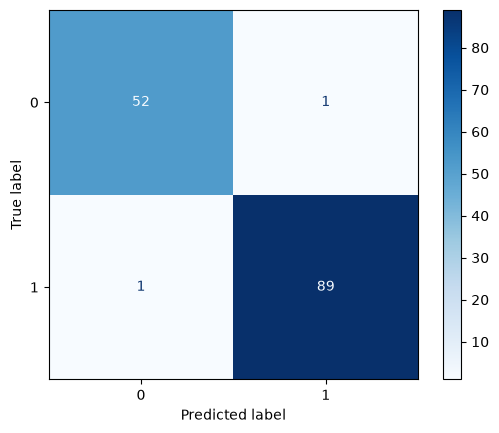

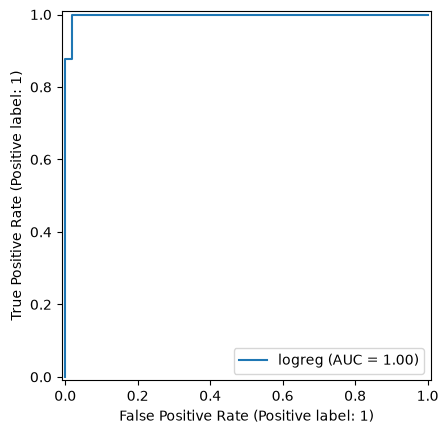

Артефакты добавлены в запуск 9bc06a1756634c87b328c600c863c0d4


In [25]:
from sklearn.metrics import RocCurveDisplay

cancer_best_model = mlflow.sklearn.load_model(cancer_best_uri)
with mlflow.start_run(run_id=cancer_best_run_id):
    cm = ConfusionMatrixDisplay.from_predictions(yc_test, cancer_best_model.predict(Xc_test), cmap="Blues")
    mlflow.log_figure(cm.figure_, "confusion_matrix.png")
    display(cm.figure_)
    plt.close(cm.figure_)
    roc = RocCurveDisplay.from_predictions(
        yc_test, cancer_best_model.predict_proba(Xc_test)[:, 1], name=cancer_best["tags.model_type"])
    mlflow.log_figure(roc.figure_, "roc_curve.png")
    display(roc.figure_)
    plt.close(roc.figure_)
print("Артефакты добавлены в запуск", cancer_best_run_id)


### Задача 4. Кривая обучения
Обучите `SGDClassifier(loss="log_loss", random_state=42)` на Breast Cancer 40 эпохами (`partial_fit`)
и после каждой эпохи записывайте `train_accuracy` и `val_accuracy` со `step=epoch`.
Потом через `get_metric_history` найдите эпоху с лучшим `val_accuracy`. Посмотрите график в интерфейсе.

Лучший step=16 (эпоха 17), val_accuracy=0.9860


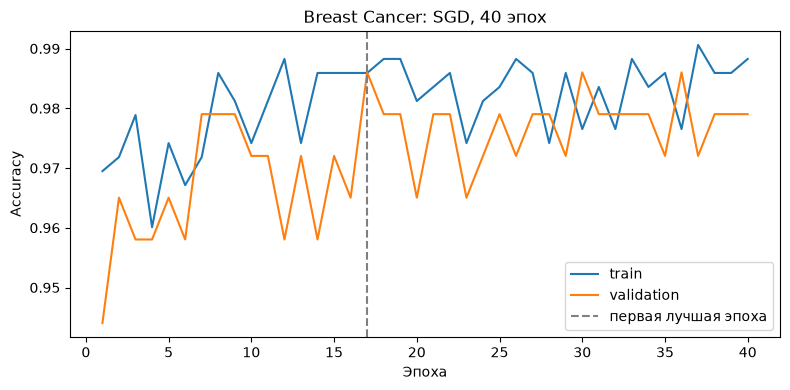

In [26]:
cancer_scaler = StandardScaler().fit(Xc_train)
Xc_tr = cancer_scaler.transform(Xc_train)
Xc_te = cancer_scaler.transform(Xc_test)
cancer_classes = np.unique(yc_train)
with mlflow.start_run(run_name="sgd_40_epochs") as sgd_run:
    mlflow.log_params({"loss": "log_loss", "random_state": 42, "epochs": 40})
    cancer_sgd = SGDClassifier(loss="log_loss", random_state=42)
    for epoch in range(40):
        cancer_sgd.partial_fit(Xc_tr, yc_train, classes=cancer_classes)
        mlflow.log_metrics({
            "train_accuracy": cancer_sgd.score(Xc_tr, yc_train),
            "val_accuracy": cancer_sgd.score(Xc_te, yc_test),
        }, step=epoch)

client = mlflow.MlflowClient()
val_history = sorted(client.get_metric_history(sgd_run.info.run_id, "val_accuracy"), key=lambda m: m.step)
train_history = sorted(client.get_metric_history(sgd_run.info.run_id, "train_accuracy"), key=lambda m: m.step)
assert len(val_history) == len(train_history) == 40
best_epoch = max(val_history, key=lambda m: (m.value, -m.step))
print(f"Лучший step={best_epoch.step} (эпоха {best_epoch.step + 1}), val_accuracy={best_epoch.value:.4f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([m.step + 1 for m in train_history], [m.value for m in train_history], label="train")
ax.plot([m.step + 1 for m in val_history], [m.value for m in val_history], label="validation")
ax.axvline(best_epoch.step + 1, color="gray", linestyle="--", label="первая лучшая эпоха")
ax.set(xlabel="Эпоха", ylabel="Accuracy", title="Breast Cancer: SGD, 40 эпох")
ax.legend()
fig.tight_layout()
with mlflow.start_run(run_id=sgd_run.info.run_id):
    mlflow.log_figure(fig, "learning_curve.png")
display(fig)
plt.close(fig)


### Задача 5. Реестр
Зарегистрируйте лучшую модель из задачи 2 как `f"{MLFLOW_USER}_cancer_model"`, поставьте ей метку `champion`,
загрузите по адресу `models:/…@champion` и сделайте прогноз для первых 5 строк теста.

In [27]:
CANCER_MODEL_NAME = f"{MLFLOW_USER}_cancer_model"
cancer_version = mlflow.register_model(cancer_best_uri, CANCER_MODEL_NAME)
client.set_registered_model_alias(CANCER_MODEL_NAME, "champion", cancer_version.version)
cancer_champion = mlflow.sklearn.load_model(f"models:/{CANCER_MODEL_NAME}@champion")
champion_predictions = cancer_champion.predict(Xc_test.head(5))
np.testing.assert_array_equal(champion_predictions, cancer_best_model.predict(Xc_test.head(5)))
print("Версия:", cancer_version.version, "| champion:", champion_predictions)
print("Правильные классы:", yc_test.head(5).tolist())


Successfully registered model 'local_student_cancer_model'.
2026/11/13 00:53:03 WARNING mlflow.tracking._model_registry.fluent: Run with id 9bc06a1756634c87b328c600c863c0d4 has no artifacts at artifact path 'model', registering model based on models:/m-43157c0e69804cada9debdb2f2c2cb22 instead


Версия: 1 | champion: [1 0 1 1 0]
Правильные классы: [1, 0, 1, 1, 0]


Created version '1' of model 'local_student_cancer_model'.


### Задача 6 ★. Ворота качества
Обучите новую модель — `RandomForestClassifier(n_estimators=500, max_depth=5, random_state=42)`.
Узнайте `roc_auc` текущего чемпиона (метка → версия → запуск → метрика) и сравните.
Зарегистрируйте новую модель и переставьте `champion` на неё **только если она лучше**.
Напечатайте, кто в итоге чемпион. Так работает автоматический выпуск моделей в конвейере Airflow.

In [28]:
champion_version_before = client.get_model_version_by_alias(CANCER_MODEL_NAME, "champion")
champion_run = client.get_run(champion_version_before.run_id)
champion_auc = champion_run.data.metrics["roc_auc"]
with mlflow.start_run(run_name="candidate_rf_500_depth5") as candidate_run:
    candidate_params = {"n_estimators": 500, "max_depth": 5, "random_state": 42}
    mlflow.log_params(candidate_params)
    mlflow.set_tag("model_type", "random_forest")
    candidate = make_pipeline(StandardScaler(), RandomForestClassifier(**candidate_params))
    candidate.fit(Xc_train, yc_train)
    candidate_auc = roc_auc_score(yc_test, candidate.predict_proba(Xc_test)[:, 1])
    mlflow.log_metric("roc_auc", candidate_auc)
    candidate_info = log_sklearn_model(candidate, Xc_test)
    passed = candidate_auc > champion_auc
    mlflow.set_tag("quality_gate_passed", str(passed).lower())
    mlflow.log_metric("champion_roc_auc_before", champion_auc)

if passed:
    new_version = mlflow.register_model(candidate_info.model_uri, CANCER_MODEL_NAME)
    client.set_registered_model_alias(CANCER_MODEL_NAME, "champion", new_version.version)
    print("Кандидат лучше: зарегистрирована новая версия и обновлён champion")
else:
    print("Кандидат не лучше: новая версия не зарегистрирована, champion сохранён")
final_champion = client.get_model_version_by_alias(CANCER_MODEL_NAME, "champion")
final_champion_run = client.get_run(final_champion.run_id)
print(f"ROC-AUC: кандидат={candidate_auc:.6f}, прежний champion={champion_auc:.6f}")
print("Итоговый champion:", CANCER_MODEL_NAME, "версия", final_champion.version,
      "| run:", final_champion.run_id, "| ROC-AUC:", final_champion_run.data.metrics["roc_auc"])


Кандидат не лучше: новая версия не зарегистрирована, champion сохранён
ROC-AUC: кандидат=0.993291, прежний champion=0.997694
Итоговый champion: local_student_cancer_model версия 1 | run: 9bc06a1756634c87b328c600c863c0d4 | ROC-AUC: 0.9976939203354298


### Задача 7. Три модели параллельно под одним родителем
Сделайте родительский запуск `parallel_cancer` в `CANCER_EXP`. Внутри него **параллельно** (3 потока)
обучите три дочерние модели: логистическую регрессию, `RandomForestClassifier(random_state=42)`
и `KNeighborsClassifier()` (со стандартизацией). В каждой запишите `roc_auc`.
В родителя запишите `best_model` и `best_roc_auc`. Проверьте в интерфейсе, что под родителем три дочерних запуска.

In [29]:
from concurrent.futures import ThreadPoolExecutor
from threading import Barrier

parallel_models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "random_forest": make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42)),
    "knn": make_pipeline(StandardScaler(), KNeighborsClassifier()),
}
ready_to_train = Barrier(3)

def train_cancer_child(item, parent_id, experiment_id):
    name, estimator = item
    # Отдельный клиент на поток и явные run_id: без общего fluent-состояния.
    child_client = mlflow.MlflowClient()
    child = child_client.create_run(experiment_id, tags={
        "mlflow.runName": f"parallel_{name}",
        "mlflow.parentRunId": parent_id,
        "model_type": name,
    })
    child_id = child.info.run_id
    try:
        ready_to_train.wait(timeout=60)
        started = time.perf_counter()
        estimator.fit(Xc_train, yc_train)
        auc = roc_auc_score(yc_test, estimator.predict_proba(Xc_test)[:, 1])
        finished = time.perf_counter()
        child_client.log_metric(child_id, "roc_auc", auc)
        child_client.set_terminated(child_id, status="FINISHED")
        return {"model": name, "roc_auc": auc, "run_id": child_id,
                "start": started, "end": finished}
    except Exception:
        ready_to_train.abort()
        child_client.set_terminated(child_id, status="FAILED")
        raise

with mlflow.start_run(run_name="parallel_cancer", experiment_id=cancer_experiment_id) as cancer_parent:
    mlflow.log_param("dataset", "breast_cancer")
    with ThreadPoolExecutor(max_workers=3) as pool:
        futures = [pool.submit(train_cancer_child, item, cancer_parent.info.run_id, cancer_experiment_id)
                   for item in parallel_models.items()]
        parallel_results = [future.result() for future in futures]
    parallel_best = max(parallel_results, key=lambda row: row["roc_auc"])
    mlflow.log_param("best_model", parallel_best["model"])
    mlflow.log_metric("best_roc_auc", parallel_best["roc_auc"])

children = mlflow.search_runs(experiment_ids=[cancer_experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{cancer_parent.info.run_id}'")
assert len(children) == 3 and set(children["status"]) == {"FINISHED"}
display(pd.DataFrame(parallel_results))
print("Родитель:", cancer_parent.info.run_id, "| дочерних запусков:", len(children))
print("Лучшая:", parallel_best["model"], "| ROC-AUC:", parallel_best["roc_auc"])


,model,roc_auc,run_id,start,end
0,logreg,0.997694,5ea589b4aa0942998dfe16b7e7fb5e78,29982.094307,29982.124215
1,random_forest,0.995073,35d878f189a8478298bed20cd66ffa47,29982.093905,29982.205262
2,knn,0.984486,43d832d508f448f0a273aa8b5248a6a9,29982.095797,29982.123859


Родитель: 927f0e56b228496e851e2e2c7f89ffe4 | дочерних запусков: 3
Лучшая: logreg | ROC-AUC: 0.9976939203354298


### Задача 8. Интерфейс
Откройте **http://10.162.1.86:5000**, эксперимент `…_cancer`:
1. отметьте запуски `cmp_*` и нажмите **Compare** — какая модель лучше и насколько?
2. откройте запуск `sgd_40_epochs` → вкладка **Model metrics**: где начинается переобучение?
4. откройте **Models** → свою модель: сколько версий и у какой метка `champion`?

---
**Готово?** Следующий шаг — Airflow: тот же код запускается сам, по расписанию, и каждая задача DAG-а
пишет свой запуск в MLflow.

### Решение задачи 8: сравнение и анализ результатов

Численные ответы ниже получаются из сохранённых запусков, а не задаются вручную.
Для локального веб-интерфейса запустите команду из раздела 2 и откройте http://127.0.0.1:5000.
Compare показывает ту же тройку `cmp_*`, график `sgd_40_epochs` — те же 40 значений.
Признак переобучения — устойчивый рост train при ухудшении validation;
отдельное колебание или первая лучшая эпоха сами по себе не определяют его начало.
Оценка на этой тестовой части используется для выбора по условию лабораторной;
для независимой итоговой оценки нужна отдельная, не участвовавшая в выборе выборка.


In [30]:
comparison_summary = cancer_runs[["tags.model_type", "metrics.roc_auc"]].copy()
display(comparison_summary)
gap = cancer_runs.iloc[0]["metrics.roc_auc"] - cancer_runs.iloc[1]["metrics.roc_auc"]
print(f"Победитель: {cancer_best['tags.model_type']}; отрыв от второго места по ROC-AUC: {gap:.6f}")
epoch_table = pd.DataFrame({
    "epoch": [m.step + 1 for m in val_history],
    "train_accuracy": [m.value for m in train_history],
    "val_accuracy": [m.value for m in val_history],
})
display(epoch_table)
print(f"Первая лучшая эпоха: {best_epoch.step + 1}; validation={best_epoch.value:.4f}.")
print("Начало переобучения оценивайте по устойчивому расхождению кривых выше, не по одному спаду.")
registry_versions = list(client.search_model_versions(f"name='{CANCER_MODEL_NAME}'"))
champion_now = client.get_model_version_by_alias(CANCER_MODEL_NAME, "champion")
print("Версий в реестре:", len(registry_versions), "| champion у версии:", champion_now.version)
print("Эксперимент:", f"{UI}/#/experiments/{cancer_experiment_id}")


,tags.model_type,metrics.roc_auc
0,logreg,0.997694
1,random_forest,0.995073
2,knn,0.984486


Победитель: logreg; отрыв от второго места по ROC-AUC: 0.002621


,epoch,train_accuracy,val_accuracy
0,1,0.969484,0.944056
1,2,0.971831,0.965035
2,3,0.978873,0.958042
3,4,0.960094,0.958042
4,5,0.974178,0.965035
5,6,0.967136,0.958042
6,7,0.971831,0.979021
7,8,0.985915,0.979021
8,9,0.981221,0.979021
9,10,0.974178,0.972028


Первая лучшая эпоха: 17; validation=0.9860.
Начало переобучения оценивайте по устойчивому расхождению кривых выше, не по одному спаду.
Версий в реестре: 1 | champion у версии: 1
Эксперимент: http://127.0.0.1:5000/#/experiments/3


### Вывод по выполненному локальному запуску

- Лучшая модель — логистическая регрессия: ROC-AUC **0.997694**, случайный лес — **0.995073**, KNN — **0.984486**. Отрыв от второго места — **0.002621**.
- У SGD максимум validation accuracy **0.986014** впервые достигнут на **17-й эпохе** (step=16) и повторяется на 30-й и 36-й. Устойчивого падения validation при непрерывном росте train нет: однозначную эпоху начала переобучения по этому запуску выделить нельзя. Колебания после 17-й эпохи сами по себе не доказывают переобучение.
- В реестре создана **1 версия**, alias **champion** у версии **1** (логистическая регрессия). Кандидат RF с 500 деревьями и глубиной 5 получил ROC-AUC **0.993291**, поэтому ворота качества его отклонили.
- Родитель `parallel_cancer` содержит **3 завершённых дочерних запуска**; победитель также `logreg`.

Эти значения относятся к сохранённому локальному запуску и установленным версиям библиотек; актуальные результаты при повторном выполнении выводятся ячейками выше.